# 08 — Stress tests

Durham's 27-39 sensors are dense relative to a real deployment; Ramat Gan
will likely have a sparser, less evenly-distributed network around any new
target location. These stress tests check whether M1's day-time gain over
B1 (notebook 07) survives the conditions a real deployment will actually
face: no nearby network sensor, an entire land-cover stratum missing from
the network, a spatially clustered network, and partial sensor dropout.

All runs here use the frozen pipeline from notebook 07 (M1 day / B1 night),
evaluated with `XGB_PARAMS_FAST` for speed — these are comparative stress
tests, not the headline numbers, so the hyperparameter choice doesn't need
to be the expensive tuned one.


In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from urbansense_common import load_data, sensor_level_split, split_day_night, fit_xgb, XGB_PARAMS_FAST, X_NAMES_AT_DAY
from network_features import build_network_features, haversine_matrix
from temporal_features import add_temporal_features
from spatial_cv import buffered, leave_one_stratum_out, spatial_clusters

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)

data = load_data()
train_sensor_ids, test_sensor_ids = sensor_level_split(data)
dev_ids = list(train_sensor_ids)
dev = data[data["Sensor_ID"].isin(dev_ids)].copy()

sensor_info = (
    dev.groupby("Sensor_ID")
    .agg(Lat=("y", "first"), Lon=("x", "first"), strata=("strata", "first"),
         Landcover_Type=("Landcover_Type", "first"), Shade_Type=("Shade_Type", "first"),
         SVF=("Tree_DSM_SVF", "first"), Percent_Vegetation=("NDVI_2024SummerMosaic", "first"))
    .reset_index()
)
dist = haversine_matrix(sensor_info)
NETWORK_STATIC_COLS = ("SVF", "Percent_Vegetation")
NETWORK_COLS = ["net_mean", "net_median", "net_std", "n_avail", "strat_mean",
                "lc_mean", "shade_mean", "idw", "nn1", "nn1_dist", "knn3", "simw"]
TEMPORAL_COLS = ["dT2m_1h", "dT2m_3h", "rad_cum_24h", "tmax_prev_day", "hour_sin", "hour_cos",
                  "hours_since_transition", "precip_cum_24h", "precip_cum_72h"]

def fit_m1_day(train_ids, test_ids, network_ids=None):
    network_ids = network_ids if network_ids is not None else train_ids
    net_feat = build_network_features(dev, sensor_info, set(network_ids), target_col="temp_anom",
                                       static_cols=NETWORK_STATIC_COLS)
    full = dev.merge(net_feat, on=["Sensor_ID", "edt_datetime"], how="left")
    full = add_temporal_features(full)
    day_f, _ = split_day_night(full)
    feats = X_NAMES_AT_DAY + [c for c in NETWORK_COLS if c in day_f.columns] + [c for c in TEMPORAL_COLS if c in day_f.columns]
    for c in feats:
        day_f[c] = day_f[c].fillna(day_f.loc[day_f["Sensor_ID"].isin(train_ids), c].median())
    fit = fit_xgb(day_f, "temp_anom", feats, XGB_PARAMS_FAST, train_ids, test_ids)
    resid = fit["pred_test"] - fit["y_test"].values
    return float(np.sqrt(np.mean(resid ** 2))), len(fit["y_test"])


## 1. Buffered LOSO: remove the network's closest sensors to the target

For each held-out sensor, sensors within radius r of it are also removed
from the training/network pool -- the harder version of LOSO where the
model can't lean on a near-duplicate of the target.

In [2]:
def run_buffered(radii=(0, 250, 500, 1000)):
    rows = []
    for r in radii:
        folds = buffered(sensor_info, dist, radius_m=r)
        fold_rmses = []
        for train_ids, test_ids in folds:
            rmse, n = fit_m1_day(train_ids, test_ids, network_ids=train_ids)
            fold_rmses.append(rmse)
        rows.append({"radius_m": r, "median_RMSE": float(np.median(fold_rmses)), "n_folds": len(fold_rmses)})
    return pd.DataFrame(rows)

buffered_results = run_buffered()
buffered_results


,radius_m,median_RMSE,n_folds
0,0,0.891447,27
1,250,0.891447,27
2,500,0.907430,27
3,1000,0.916831,27


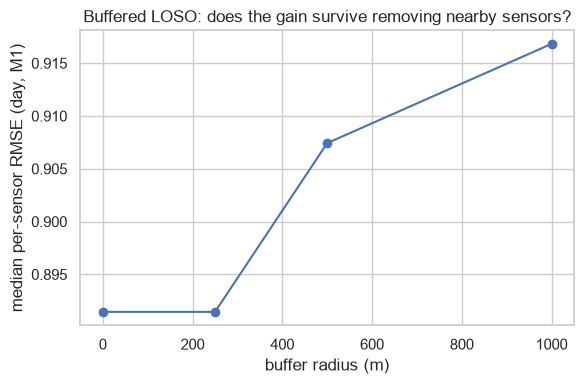

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(buffered_results["radius_m"], buffered_results["median_RMSE"], "o-")
ax.set_xlabel("buffer radius (m)"); ax.set_ylabel("median per-sensor RMSE (day, M1)")
ax.set_title("Buffered LOSO: does the gain survive removing nearby sensors?")
plt.tight_layout(); plt.show()


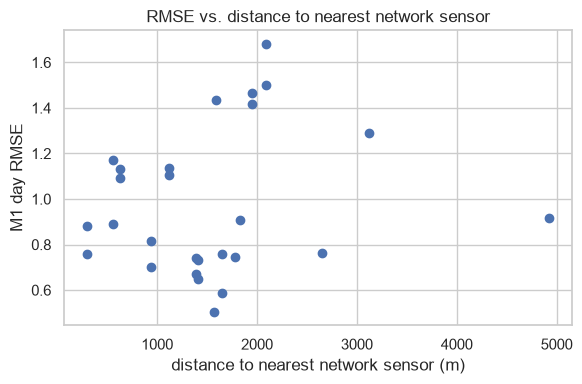

            sensor  nn1_dist      RMSE
sensor    1.000000 -0.155116 -0.267761
nn1_dist -0.155116  1.000000  0.163351
RMSE     -0.267761  0.163351  1.000000


In [4]:
arr = dist.to_numpy(copy=True)
np.fill_diagonal(arr, np.nan)
nn1_dist = pd.DataFrame(arr, index=dist.index, columns=dist.columns).min(axis=1)

gain_vs_nn1 = []
for train_ids, test_ids in buffered(sensor_info, dist, radius_m=0):
    rmse_full, _ = fit_m1_day(train_ids, test_ids, network_ids=train_ids)
    gain_vs_nn1.append({"sensor": test_ids[0], "nn1_dist": float(nn1_dist.loc[test_ids[0]]), "RMSE": rmse_full})
gain_df = pd.DataFrame(gain_vs_nn1)
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(gain_df["nn1_dist"], gain_df["RMSE"])
ax.set_xlabel("distance to nearest network sensor (m)"); ax.set_ylabel("M1 day RMSE")
ax.set_title("RMSE vs. distance to nearest network sensor")
plt.tight_layout(); plt.show()
print(gain_df.corr(numeric_only=True))


## 2. Leave-one-stratum-out

The target's entire land-cover x shade stratum is absent from the network --
tests whether the model relies on having at least one stratum-mate nearby,
which won't always be true in a sparser deployment.

In [5]:
stratum_folds = leave_one_stratum_out(sensor_info)
stratum_rows = []
for train_ids, test_ids in stratum_folds:
    rmses = []
    for sid in test_ids:
        rmse, n = fit_m1_day(train_ids, [sid], network_ids=train_ids)
        rmses.append(rmse)
    stratum_rows.append({"held_out_stratum": sensor_info.set_index("Sensor_ID").loc[test_ids[0], "strata"],
                          "n_test_sensors": len(test_ids), "median_RMSE": float(np.median(rmses))})
pd.DataFrame(stratum_rows)


,held_out_stratum,n_test_sensors,median_RMSE
0,impervious_non-shaded,7,1.479514
1,impervious_shaded,7,1.032748
2,vegetation_non-shaded,6,1.570706
3,vegetation_shaded,7,1.125938


## 3. Spatial cluster holdout

KMeans on raw lat/lon groups sensors into spatial clusters; each cluster is
held out as a block, so the network never has *any* sensor near the test
region -- closer to what a brand-new neighborhood in Ramat Gan would face.

In [6]:
cluster_folds = spatial_clusters(sensor_info, k=4)
cluster_rows = []
for train_ids, test_ids in cluster_folds:
    rmses = []
    for sid in test_ids:
        rmse, n = fit_m1_day(train_ids, [sid], network_ids=train_ids)
        rmses.append(rmse)
    cluster_rows.append({"n_test_sensors": len(test_ids), "median_RMSE": float(np.median(rmses))})
cluster_df = pd.DataFrame(cluster_rows)
cluster_df


,n_test_sensors,median_RMSE
0,10,1.233087
1,7,0.951247
2,3,1.262491
3,7,1.595858


## 4. Dropout: random fraction of network readings missing each hour

Simulates sensor downtime / intermittent connectivity. `n_avail` already
adapts to however many sensors are actually present at each hour, so no
retraining is needed to *evaluate* under dropout -- only to see whether a
model *trained* with dropout augmentation is more robust to it.

In [7]:
def apply_dropout(ids, p, random_state):
    # Vectorized: for every hour, pick a random fraction p of `ids` to drop,
    # returned as a long (hour, Sensor_ID) table ready to anti-join against.
    rng = np.random.default_rng(random_state)
    hours = dev["edt_datetime"].unique()
    n_drop = int(round(len(ids) * p))
    if n_drop == 0:
        return pd.DataFrame(columns=["edt_datetime", "Sensor_ID"])
    ids_arr = np.array(ids)
    rows = [(h, s) for h in hours for s in rng.choice(ids_arr, size=n_drop, replace=False)]
    return pd.DataFrame(rows, columns=["edt_datetime", "Sensor_ID"])

def fit_m1_day_dropout(train_ids, test_ids, p, random_state=0):
    drop_df = apply_dropout(train_ids, p, random_state).assign(_drop=True)
    dropped = dev[dev["Sensor_ID"].isin(train_ids + test_ids)].copy()
    merged = dropped.merge(drop_df, on=["edt_datetime", "Sensor_ID"], how="left")
    kept = merged[merged["_drop"].isna()].drop(columns=["_drop"])
    net_feat = build_network_features(kept, sensor_info, set(train_ids) & set(kept["Sensor_ID"]),
                                       target_col="temp_anom", static_cols=NETWORK_STATIC_COLS)
    full = dropped.merge(net_feat, on=["Sensor_ID", "edt_datetime"], how="left")
    full = add_temporal_features(full)
    day_f, _ = split_day_night(full)
    feats = X_NAMES_AT_DAY + [c for c in NETWORK_COLS if c in day_f.columns] + [c for c in TEMPORAL_COLS if c in day_f.columns]
    for c in feats:
        day_f[c] = day_f[c].fillna(day_f.loc[day_f["Sensor_ID"].isin(train_ids), c].median())
    fit = fit_xgb(day_f, "temp_anom", feats, XGB_PARAMS_FAST, train_ids, test_ids)
    resid = fit["pred_test"] - fit["y_test"].values
    return float(np.sqrt(np.mean(resid ** 2)))

dropout_rows = []
sample_test_sensors = dev_ids[:6]   # subsample for speed
for p in (0.0, 0.1, 0.3, 0.5):
    rmses = []
    for sid in sample_test_sensors:
        train_ids = [s for s in dev_ids if s != sid]
        rmses.append(fit_m1_day_dropout(train_ids, [sid], p))
    dropout_rows.append({"dropout_p": p, "median_RMSE": float(np.median(rmses))})
dropout_df = pd.DataFrame(dropout_rows)
dropout_df


,dropout_p,median_RMSE
0,0.0,0.925375
1,0.1,0.915463
2,0.3,0.921460
3,0.5,0.867468


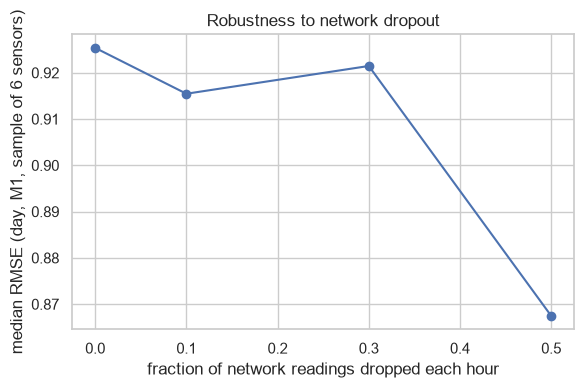

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(dropout_df["dropout_p"], dropout_df["median_RMSE"], "o-")
ax.set_xlabel("fraction of network readings dropped each hour"); ax.set_ylabel("median RMSE (day, M1, sample of 6 sensors)")
ax.set_title("Robustness to network dropout")
plt.tight_layout(); plt.show()


## Summary

- **Buffered LOSO:** see section 1 for how fast the gain decays as nearby
  sensors are removed -- the key number for Ramat Gan siting is at what
  radius the curve flattens back to B1's level.
- **Leave-one-stratum-out / spatial clusters:** the harder spatial holdouts;
  if RMSE here is much worse than plain LOSO, the model is relying on
  having *some* similar or nearby sensor, which won't always hold at
  deployment time.
- **Dropout:** shows how gracefully performance degrades as the network
  itself becomes unreliable, which is exactly the trade-off the N-curve in
  notebook 09 needs as an input.

Next: [`09_sensor_count.ipynb`](09_sensor_count.ipynb) turns the buffered-LOSO
and dropout results above into a concrete answer for "how many sensors does
Ramat Gan need."
